# EDA of match_features

What in `match_features.csv` says anything about the result, before kick-off?
Run `uv run collect_data` and `uv run clean_data` first; this notebook only reads
`match_features.csv` and `missing.csv` from `settings.clean.out_dir`.

0. Columns: the target, the features, and the columns that leak the result
1. The target, and the baseline any model has to beat
2. What is missing, and whether being missing says something
3. One feature at a time: drift across seasons, and its link to H/D/A
4. Features together: overlap, and what is left once Elo is known
5. Summary for feature_importance (issue #13)

Everything below looks only at the training seasons (`season_start < TEST_FROM`),
so the test seasons stay unseen until the model is scored on them.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.preprocessing import StandardScaler

from money_printer_research.analysis.feature_importance import POST_MATCH, TEST_FROM, feature_group
from money_printer_research.config import settings
from money_printer_research.schema import FormationCols, TeamFatigueCols, TeamScheduleCols
from money_printer_research.schema.match.features import PLAYER_SLOT_FEATURES, slot_columns

pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_rows(30)
plt.rcParams["figure.dpi"] = 110

TARGET = "full_time_result"
OUTCOMES = ["H", "D", "A"]

matches = pl.read_csv(
    settings.clean.out_dir / "match_features.csv", infer_schema_length=None, try_parse_dates=True
)
missing = pl.read_csv(settings.clean.out_dir / "missing.csv")
print(matches.shape, missing.shape)

(21589, 174) (115861, 4)


## 0. Columns

Features are listed by where they come from, not by "every column but a few": a new
column then has to be added here on purpose. The goals and xG of the match itself
are known only after it, so they must never be features; the assert below fails if
one slips in.

In [2]:
ELO = ["elo_home", "elo_away", "elo_diff"]
FATIGUE = [c for c in TeamFatigueCols.to_schema().columns if c != "game_id"]
SCHEDULE = [c for c in TeamScheduleCols.to_schema().columns if c != "game_id"]
FORMATION = [
    c
    for c, col in FormationCols.to_schema().columns.items()
    if col.dtype is not None and str(col.dtype) not in {"String", "Utf8"}
]
SLOTS = list(slot_columns())
FEATURES = [c for c in [*ELO, *FATIGUE, *SCHEDULE, *FORMATION, *SLOTS] if c in matches.columns]

LEAKS = re.compile(POST_MATCH.pattern + r"|^(home|away)_goals$|^tm_(home|away)_goals$|^is_result$")
leaking = [c for c in FEATURES if LEAKS.match(c)]
assert not leaking, leaking

absent = sorted({*ELO, *FATIGUE, *SCHEDULE, *FORMATION, *SLOTS} - set(matches.columns))
print("features:", len(FEATURES), "| expected but absent:", absent)
print("never features (post-match):", [c for c in matches.columns if LEAKS.match(c)])

pl.DataFrame({"column": FEATURES}).group_by(
    pl.col("column").map_elements(feature_group, return_dtype=pl.String).alias("group")
).len().sort("len", descending=True)

features: 140 | expected but absent: []
never features (post-match): ['home_goals', 'away_goals', 'home_xg', 'away_xg', 'is_result', 'tm_home_goals', 'tm_away_goals', 'full_time_result']


group,len
str,u32
"""player_prev_min""",22
"""player_xa90""",22
"""player_fatigue_score""",22
"""player_form90""",22
"""player_xg90""",22
"""elo""",3
"""games_14d_all""",2
"""non_league_14d""",2
"""next_is_europe""",2


In [3]:
train = matches.filter(pl.col("season_start") < TEST_FROM)
print("train:", train.height, "games,", train["season_start"].n_unique(), "seasons")
print("held out (not looked at):", matches.height - train.height, "games")

train: 18085 games, 10 seasons
held out (not looked at): 3504 games


## 1. The target

Share of H/D/A per league and season. The 2020/21 seasons were played without crowds:
if home advantage is real, the home share should dip there.

In [4]:
shares = (
    train.group_by("league", "season_start", TARGET)
    .len()
    .with_columns(
        (pl.col("len") / pl.col("len").sum().over("league", "season_start")).alias("share")
    )
    .pivot(on=TARGET, index=["league", "season_start"], values="share")
    .select("league", "season_start", *OUTCOMES)
    .sort("league", "season_start")
)
shares

league,season_start,H,D,A
str,i64,f64,f64,f64
"""ENG-Premier League""",2014,0.452632,0.244737,0.302632
"""ENG-Premier League""",2015,0.413158,0.281579,0.305263
"""ENG-Premier League""",2016,0.492105,0.221053,0.286842
"""ENG-Premier League""",2017,0.455263,0.260526,0.284211
"""ENG-Premier League""",2018,0.476316,0.186842,0.336842
"""ENG-Premier League""",2019,0.452632,0.242105,0.305263
"""ENG-Premier League""",2020,0.378947,0.218421,0.402632
"""ENG-Premier League""",2021,0.428947,0.231579,0.339474
"""ENG-Premier League""",2022,0.484211,0.228947,0.286842


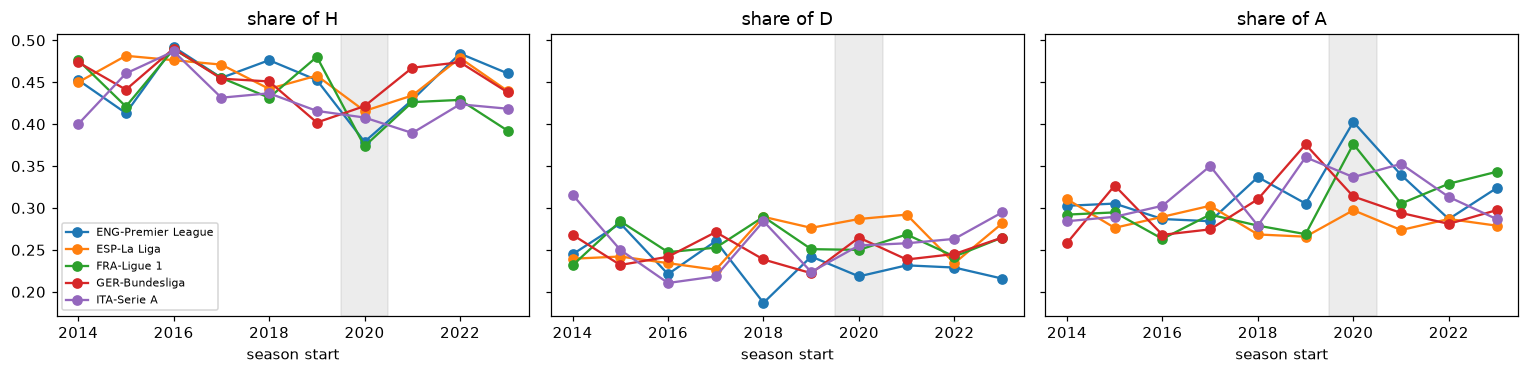

In [5]:
leagues = shares["league"].unique().sort().to_list()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, outcome in zip(axes, OUTCOMES, strict=True):
    for league in leagues:
        s = shares.filter(pl.col("league") == league)
        ax.plot(s["season_start"], s[outcome], marker="o", label=league)
    ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
    ax.set_title(f"share of {outcome}")
    ax.set_xlabel("season start")
axes[0].legend(fontsize=7)
plt.tight_layout()

**Baseline.** Predict every game with the training shares of H/D/A and nothing else.
Its log loss is the bar every model has to clear; a feature that cannot beat it is noise.
Scored season by season, with shares from the seasons before it only.

In [6]:
seasons = train["season_start"].unique().sort().to_list()
rows = []
for s in seasons[1:]:
    past = train.filter(pl.col("season_start") < s)
    now = train.filter(pl.col("season_start") == s)
    prior = past[TARGET].value_counts(normalize=True)
    labels = sorted(OUTCOMES)  # log_loss reads probability columns in sorted label order
    p = [prior.filter(pl.col(TARGET) == o)["proportion"].sum() for o in labels]
    rows.append(
        {
            "season_start": s,
            "games": now.height,
            "log_loss_prior": log_loss(now[TARGET], [p] * now.height, labels=labels),
        }
    )
baseline = pl.DataFrame(rows)
baseline

season_start,games,log_loss_prior
i64,i64,f64
2015,1826,1.071235
2016,1826,1.04949
2017,1826,1.064995
2018,1826,1.069808
2019,1725,1.070087
2020,1826,1.089723
2021,1826,1.077331
2022,1826,1.063025
2023,1752,1.077193


## 2. What is missing

`missing.csv` has one row per null cell of match_features and why it is null.
`plain_shape` is expected (a formation with no variant) and left out here.

In [7]:
cells = missing.filter(pl.col("reason") != "plain_shape").join(
    matches.select("game_id", "league", "season_start", TARGET), on="game_id"
)
by_season = (
    cells.group_by("reason", "season_start")
    .len()
    .pivot(on="season_start", index="reason", values="len", sort_columns=True)
    .fill_null(0)
    .sort("reason")
)
by_season

reason,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
str,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""no_formation""",0,0,0,14,672,0,21,14,28,0,0,28
"""no_lineup""",0,0,115,0,0,0,0,0,0,0,115,0
"""no_next_game""",1,1,2,0,2,1,2,1,2,1,3,96
"""short_lineup""",30,15,0,5,0,0,0,0,5,0,0,5
"""too_few_minutes""",21888,7245,6066,5250,4971,5361,5394,5661,6168,6243,6504,6711


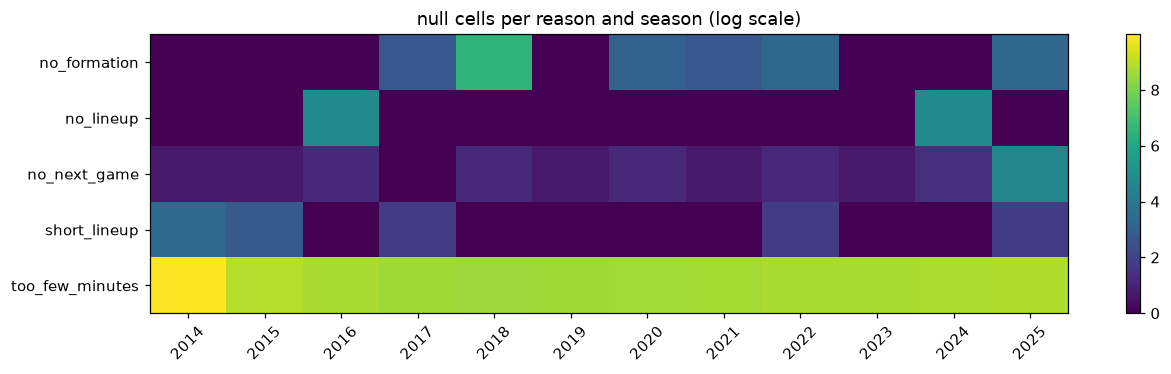

In [8]:
grid = by_season.drop("reason").to_numpy()
fig, ax = plt.subplots(figsize=(12, 0.5 * len(grid) + 1))
im = ax.imshow(np.log1p(grid), aspect="auto", cmap="viridis")
ax.set_yticks(range(len(grid)), by_season["reason"].to_list())
ax.set_xticks(range(grid.shape[1]), by_season.columns[1:], rotation=45)
ax.set_title("null cells per reason and season (log scale)")
fig.colorbar(im, ax=ax)
plt.tight_layout()

In [9]:
cells.group_by("reason", "league").len().pivot(
    on="league", index="reason", values="len", sort_columns=True
).fill_null(0).sort("reason")

reason,ENG-Premier League,ESP-La Liga,FRA-Ligue 1,GER-Bundesliga,ITA-Serie A
str,u32,u32,u32,u32,u32
"""no_formation""",0,707,56,0,14
"""no_lineup""",0,0,115,115,0
"""no_next_game""",20,20,34,18,20
"""short_lineup""",0,5,45,5,5
"""too_few_minutes""",15003,18492,20487,15516,17964


**Does being missing say something?** For each reason, compare H/D/A in the games that
have it with the games that do not. A clear gap means the null is itself a signal,
worth a flag column in the model rather than a value to fill.

In [10]:
def result_shares(df: pl.DataFrame) -> dict[str, float]:
    counts = df[TARGET].value_counts(normalize=True)
    return {o: counts.filter(pl.col(TARGET) == o)["proportion"].sum() for o in OUTCOMES}


train_cells = cells.filter(pl.col("season_start") < TEST_FROM)
rows = []
for reason in train_cells["reason"].unique().sort():
    ids = train_cells.filter(pl.col("reason") == reason)["game_id"].unique()
    has = train.filter(pl.col("game_id").is_in(ids.implode()))
    rest = train.filter(~pl.col("game_id").is_in(ids.implode()))
    rows.append(
        {"reason": reason, "games": has.height}
        | {f"{o}_with": v for o, v in result_shares(has).items()}
        | {f"{o}_without": v for o, v in result_shares(rest).items()}
    )
pl.DataFrame(rows)

reason,games,H_with,D_with,A_with,H_without,D_without,A_without
str,i64,f64,f64,f64,f64,f64,f64
"""no_formation""",54,0.296296,0.351852,0.351852,0.444179,0.251289,0.304531
"""no_lineup""",1,0.0,0.0,1.0,0.443762,0.251604,0.304634
"""no_next_game""",13,0.615385,0.153846,0.230769,0.443614,0.25166,0.304726
"""short_lineup""",10,0.3,0.2,0.5,0.443817,0.251618,0.304564
"""too_few_minutes""",10518,0.448279,0.251569,0.300152,0.437426,0.251619,0.310955


**Player slots.** `too_few_minutes` is the biggest reason: a starter with too few
previous minutes has no per-90 rates. How often is each slot usable?

In [11]:
slot_nulls = (
    train.select([c for c in SLOTS if c in train.columns])
    .null_count()
    .unpivot(variable_name="column", value_name="nulls")
    .with_columns(
        pl.col("column").str.extract(r"_player\d+_(.+)$").alias("feature"),
        pl.col("column").str.extract(r"_player(\d+)_").cast(pl.Int32).alias("slot"),
        (pl.col("nulls") / train.height).alias("null_share"),
    )
)
slot_nulls.pivot(on="feature", index="slot", values="null_share", aggregate_function="mean").sort(
    "slot"
)

slot,xg90,xa90,form90,prev_min,fatigue_score
i32,f64,f64,f64,f64,f64
1,0.045424,0.045424,0.045424,0.000055,0.000055
2,0.049184,0.049184,0.049184,0.000055,0.000055
3,0.028338,0.028338,0.028338,0.000055,0.000055
4,0.065441,0.065441,0.065441,0.000055,0.000055
5,0.061709,0.061709,0.061709,0.000055,0.000055
6,0.051756,0.051756,0.051756,0.000055,0.000055
7,0.056013,0.056013,0.056013,0.000055,0.000055
8,0.079099,0.079099,0.079099,0.000055,0.000055
9,0.077772,0.077772,0.077772,0.000055,0.000055


## 3. One feature at a time

Home-minus-away differences first: the result depends on the gap between the sides
more than on either side alone. The player slots are averaged over the starters of
each side (`h_xg90_mean`), since 11 correlated slots spread the signal thin.

Elo starts every team level in 2014/15, so that season is warm-up and left out of
anything that uses Elo.

In [12]:
def side_mean(side: str, feature: str) -> pl.Expr:
    cols = [
        c for c in SLOTS if re.fullmatch(rf"{side}_player\d+_{feature}", c) and c in train.columns
    ]
    return pl.mean_horizontal(cols).alias(f"{side}_{feature}_mean")


def with_derived(df: pl.DataFrame) -> pl.DataFrame:
    df = df.with_columns(side_mean(side, f) for side in ("h", "a") for f in PLAYER_SLOT_FEATURES)
    return df.with_columns(
        (pl.col("h_rest_days_all") - pl.col("a_rest_days_all")).alias("rest_diff"),
        (pl.col("h_games_14d_all") - pl.col("a_games_14d_all")).alias("games_14d_diff"),
        (pl.col("h_min_7d") - pl.col("a_min_7d")).alias("min_7d_diff"),
        *[
            (pl.col(f"h_{f}_mean") - pl.col(f"a_{f}_mean")).alias(f"{f}_diff")
            for f in PLAYER_SLOT_FEATURES
        ],
    )


eda = with_derived(train).filter(pl.col("season_start") > train["season_start"].min())
KEY = [
    "elo_diff",
    "fatigue_diff",
    "rest_diff",
    "games_14d_diff",
    "min_7d_diff",
    *[f"{f}_diff" for f in PLAYER_SLOT_FEATURES],
]
eda.select(KEY).describe()

statistic,elo_diff,fatigue_diff,rest_diff,games_14d_diff,min_7d_diff,xg90_diff,xa90_diff,form90_diff,prev_min_diff,fatigue_score_diff
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",16259.0,16258.0,16259.0,16259.0,16258.0,16242.0,16242.0,16242.0,16258.0,16258.0
"""null_count""",0.0,1.0,0.0,0.0,1.0,17.0,17.0,17.0,1.0,1.0
"""mean""",-0.392243,0.1001,-0.034688,0.0008,3.320704,0.001499,0.000512,0.002011,4.059903,0.1001
"""std""",166.23138,14.712482,3.231774,0.856868,398.163026,0.065908,0.048576,0.107073,108.587806,14.712482
"""min""",-513.460266,-78.754545,-27.0,-4.0,-1741.0,-0.517738,-0.223013,-0.58755,-785.272727,-78.754545
"""25%""",-106.680785,-6.154545,-1.0,0.0,-113.0,-0.039033,-0.028379,-0.061107,-50.363636,-6.154545
"""50%""",-1.817888,0.0,0.0,0.0,0.0,0.001231,0.000152,0.001293,3.545455,0.0
"""75%""",106.833134,6.472727,1.0,0.0,118.0,0.04193,0.029217,0.065819,57.0,6.472727
"""max""",502.741233,69.027273,27.0,4.0,1809.0,0.266595,0.223664,0.427562,725.090909,69.027273


**Drift.** The median and spread of each feature per season. A feature whose scale moves
from season to season (more European games, a change in how Understat records minutes)
will not mean the same thing in the test seasons.

In [13]:
eda.group_by("season_start").agg(*[pl.col(c).median().alias(c) for c in KEY]).sort("season_start")

season_start,elo_diff,fatigue_diff,rest_diff,games_14d_diff,min_7d_diff,xg90_diff,xa90_diff,form90_diff,prev_min_diff,fatigue_score_diff
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2015,-2.759567,0.0,0.0,0.0,0.0,0.002722,0.00153,0.005815,6.545455,0.0
2016,-4.607323,0.0,0.0,0.0,0.0,0.000644,0.000214,0.003107,2.090909,0.0
2017,-0.189696,0.0,0.0,0.0,0.0,0.000166,0.000283,-0.001959,3.818182,0.0
2018,-2.180245,-0.090909,0.0,0.0,0.0,0.003088,0.001202,0.001995,3.5,-0.090909
2019,-1.206907,0.0,0.0,0.0,0.0,0.000137,-0.00037,-0.000404,5.818182,8.8818e-16
2020,1.44075,0.0,0.0,0.0,0.0,0.00135,-0.001208,-0.000867,1.409091,0.0
2021,-0.229784,0.0,0.0,0.0,0.0,0.000713,0.000136,0.00117,4.181818,0.0
2022,-4.860705,0.090909,0.0,0.0,0.0,0.000662,-0.000099,-0.000149,2.181818,0.090909
2023,1.474218,0.0,0.0,0.0,0.0,0.000688,-0.00071,0.00248,3.181818,0.0


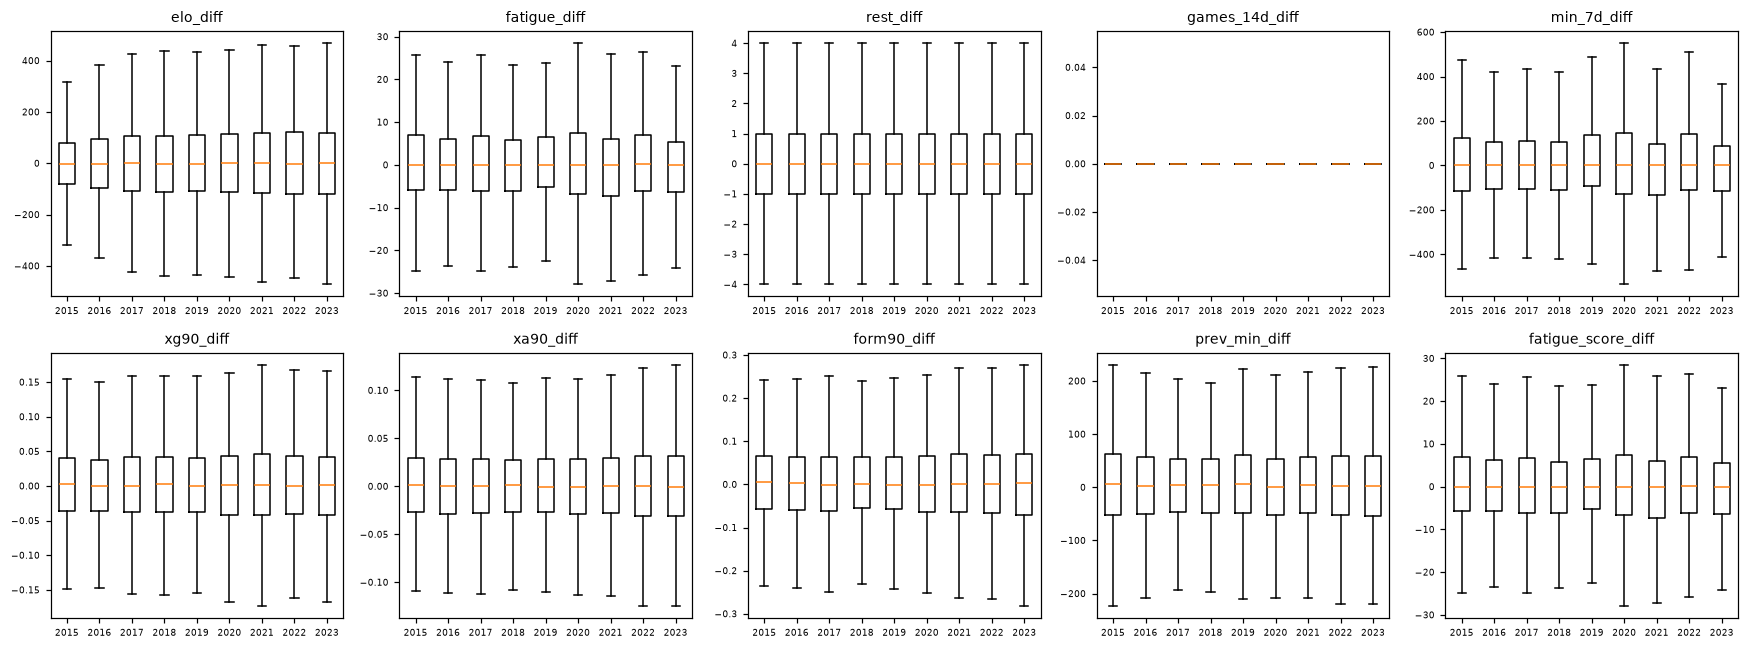

In [22]:
seasons = eda["season_start"].unique().sort().to_list()
fig, axes = plt.subplots(2, (len(KEY) + 1) // 2, figsize=(16, 6))
for ax, col in zip(axes.flat, KEY, strict=False):
    per_season = [eda.filter(pl.col("season_start") == s)[col].drop_nulls().to_numpy() for s in seasons]
    ax.boxplot(per_season, showfliers=False, tick_labels=seasons)
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=6)
for ax in axes.flat[len(KEY):]:
    ax.set_visible(False)
plt.tight_layout()

**Link to the result.** Cut each feature into deciles and plot P(H), P(D), P(A) per decile.
A flat line says nothing; a slope says the feature moves the result. `elo_diff` is the
reference: every other feature is judged against how steep it is.

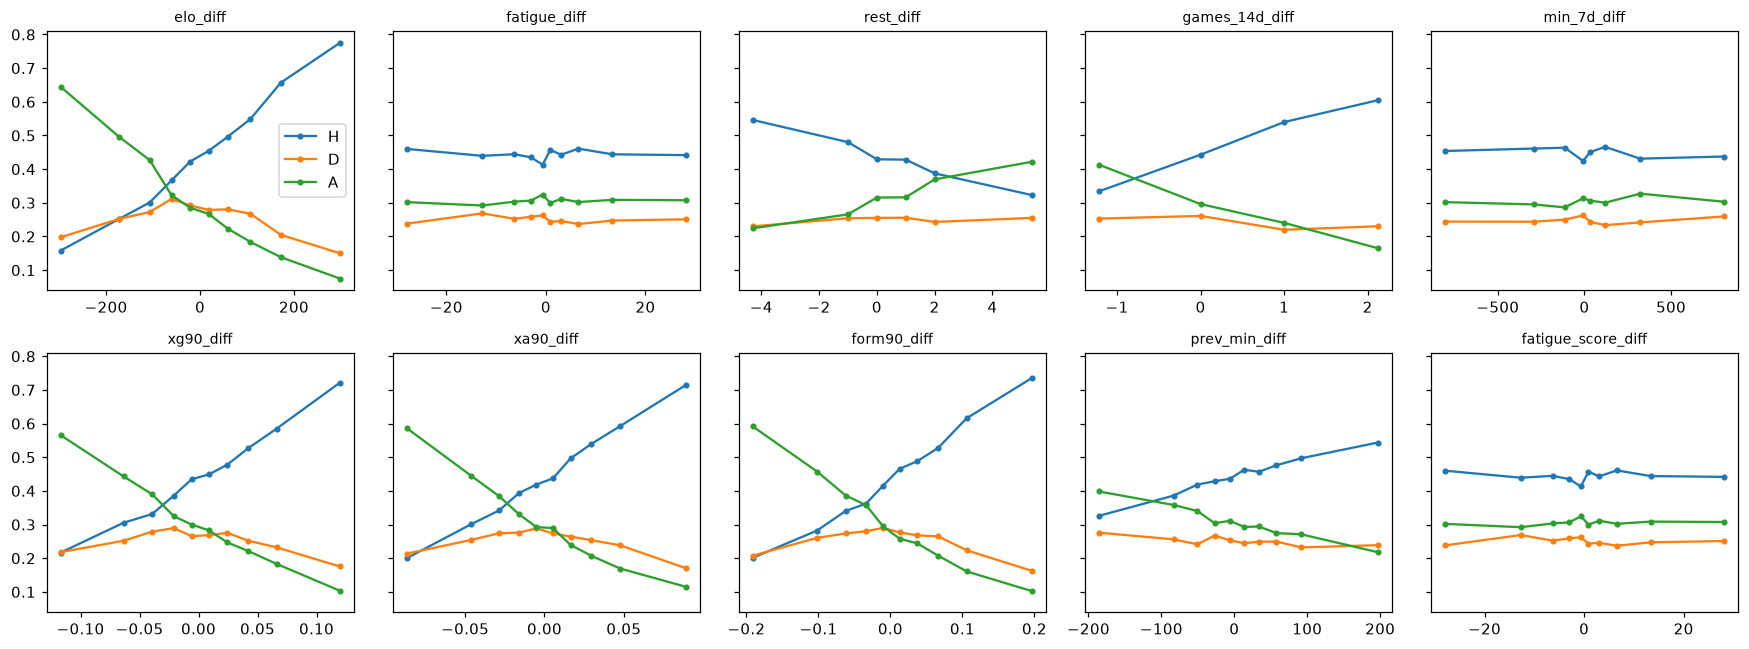

In [15]:
def by_decile(df: pl.DataFrame, col: str, q: int = 10) -> pl.DataFrame:
    return (
        df.filter(pl.col(col).is_not_null())
        .with_columns(pl.col(col).qcut(q, allow_duplicates=True).alias("bin"))
        .group_by("bin")
        .agg(
            pl.col(col).mean().alias("x"),
            pl.len().alias("games"),
            *[(pl.col(TARGET) == o).mean().alias(o) for o in OUTCOMES],
        )
        .sort("x")
    )


fig, axes = plt.subplots(2, (len(KEY) + 1) // 2, figsize=(16, 6), sharey=True)
for ax, col in zip(axes.flat, KEY, strict=False):
    d = by_decile(eda, col)
    for o in OUTCOMES:
        ax.plot(d["x"], d[o], marker=".", label=o)
    ax.set_title(col, fontsize=9)
for ax in axes.flat[len(KEY) :]:
    ax.set_visible(False)
axes.flat[0].legend()
plt.tight_layout()

**Formations.** H/D/A by the home side's shape, for shapes with enough games.

In [16]:
(
    eda.filter(pl.col("home_shape").is_not_null())
    .group_by("home_shape")
    .agg(pl.len().alias("games"), *[(pl.col(TARGET) == o).mean().alias(o) for o in OUTCOMES])
    .filter(pl.col("games") >= 100)
    .sort("games", descending=True)
)

home_shape,games,H,D,A
str,u32,f64,f64,f64
"""4-2-3-1""",4243,0.454867,0.242046,0.303087
"""4-3-3""",3082,0.499676,0.238482,0.261843
"""4-4-2""",2719,0.435086,0.260022,0.304892
"""3-5-2""",1415,0.4,0.262898,0.337102
"""3-4-2-1""",1035,0.467633,0.241546,0.290821
"""4-1-4-1""",895,0.410056,0.258101,0.331844
"""4-3-1-2""",615,0.427642,0.253659,0.318699
"""3-4-1-2""",487,0.437372,0.268994,0.293634
"""3-4-3""",413,0.457627,0.27845,0.263923


## 4. Features together

**Overlap.** Correlations between the key features, on the games where all are present.
Two features that move together carry the same information; keep the cleaner one.

games with every key feature: 16242 of 16259


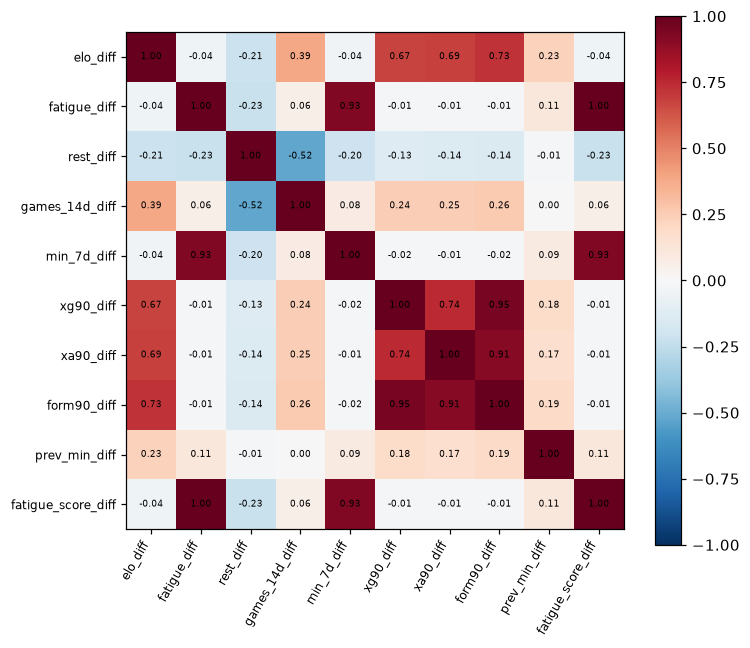

In [17]:
complete = eda.select(KEY).drop_nulls()
corr = complete.corr()
print("games with every key feature:", complete.height, "of", eda.height)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(KEY)), KEY, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(KEY)), KEY, fontsize=8)
for i in range(len(KEY)):
    for j in range(len(KEY)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax)
plt.tight_layout()

**What is left once Elo is known?** Big clubs both rate high and play in Europe, so
fatigue or schedule can look useful only because they stand in for Elo. Within each
fifth of `elo_diff`, does the feature still change P(H)?

In [18]:
def within_elo(df: pl.DataFrame, col: str) -> pl.DataFrame:
    out = (
        df.filter(pl.col(col).is_not_null())
        .with_columns(
            pl.col("elo_diff").qcut(5, labels=[f"elo q{i}" for i in range(1, 6)]).alias("elo"),
            pl.col(col).qcut(3, labels=["low", "mid", "high"], allow_duplicates=True).alias(col),
        )
        .group_by("elo", col)
        .agg((pl.col(TARGET) == "H").mean().alias("P(H)"))
        .pivot(on=col, index="elo", values="P(H)")
    )
    bins = [c for c in ("low", "mid", "high") if c in out.columns]
    return out.select("elo", *bins).sort("elo")


for col in KEY[1:]:
    print(col)
    print(within_elo(eda, col))

fatigue_diff
shape: (5, 4)
┌────────┬──────────┬──────────┬──────────┐
│ elo    ┆ low      ┆ mid      ┆ high     │
│ ---    ┆ ---      ┆ ---      ┆ ---      │
│ cat    ┆ f64      ┆ f64      ┆ f64      │
╞════════╪══════════╪══════════╪══════════╡
│ elo q1 ┆ 0.208802 ┆ 0.216342 ┆ 0.192821 │
│ elo q2 ┆ 0.322344 ┆ 0.318182 ┆ 0.36162  │
│ elo q3 ┆ 0.422825 ┆ 0.434705 ┆ 0.457277 │
│ elo q4 ┆ 0.521531 ┆ 0.512043 ┆ 0.534562 │
│ elo q5 ┆ 0.712207 ┆ 0.708758 ┆ 0.727009 │
└────────┴──────────┴──────────┴──────────┘
rest_diff
shape: (5, 3)
┌────────┬──────────┬──────────┐
│ elo    ┆ low      ┆ high     │
│ ---    ┆ ---      ┆ ---      │
│ cat    ┆ f64      ┆ f64      │
╞════════╪══════════╪══════════╡
│ elo q1 ┆ 0.20094  ┆ 0.209677 │
│ elo q2 ┆ 0.327678 ┆ 0.343987 │
│ elo q3 ┆ 0.437008 ┆ 0.441451 │
│ elo q4 ┆ 0.529967 ┆ 0.5      │
│ elo q5 ┆ 0.718929 ┆ 0.703297 │
└────────┴──────────┴──────────┘
games_14d_diff
shape: (5, 3)
┌────────┬──────────┬──────────┐
│ elo    ┆ low      ┆ high     │
│ ---  

The same question as a number: validate on the last training season, fit on the ones
before. Compare a multinomial logistic regression on `elo_diff` alone with one on
`elo_diff` plus each feature, on the same rows. A drop in log loss is what the feature
adds beyond Elo. This is a quick screen, not the model; feature_importance does that.

In [19]:
VALID = eda["season_start"].max()


def fit_score(df: pl.DataFrame, cols: list[str]) -> float:
    fit, valid = (
        df.filter(pl.col("season_start") < VALID),
        df.filter(pl.col("season_start") == VALID),
    )
    scale = StandardScaler().fit(fit.select(cols).to_numpy())
    model = LogisticRegression(max_iter=1000).fit(
        scale.transform(fit.select(cols).to_numpy()), fit[TARGET].to_numpy()
    )
    p = model.predict_proba(scale.transform(valid.select(cols).to_numpy()))
    return log_loss(valid[TARGET].to_numpy(), p, labels=model.classes_)


rows = []
for col in KEY[1:]:
    rows_ok = eda.filter(pl.col(col).is_not_null() & pl.col("elo_diff").is_not_null())
    elo_only = fit_score(rows_ok, ["elo_diff"])
    both = fit_score(rows_ok, ["elo_diff", col])
    rows.append(
        {
            "feature": col,
            "games": rows_ok.height,
            "elo_only": elo_only,
            "elo_plus": both,
            "gain": elo_only - both,
        }
    )
added = pl.DataFrame(rows).sort("gain", descending=True)
added

feature,games,elo_only,elo_plus,gain
str,i64,f64,f64,f64
"""form90_diff""",16242,0.973967,0.97002,0.003947
"""xa90_diff""",16242,0.973967,0.970098,0.003869
"""xg90_diff""",16242,0.973967,0.971605,0.002363
"""games_14d_diff""",16259,0.973956,0.974011,-0.000055
"""rest_diff""",16259,0.973956,0.974045,-0.000089
"""fatigue_diff""",16258,0.973958,0.974105,-0.000148
"""fatigue_score_diff""",16258,0.973958,0.974105,-0.000148
"""prev_min_diff""",16258,0.973958,0.974187,-0.000229
"""min_7d_diff""",16258,0.973958,0.974372,-0.000414


## 5. Summary

One row per key feature: how often it is null, how far P(H) moves from its lowest to
its highest decile, and what it adds beyond Elo. Write the conclusions below and carry
them to feature_importance (issue #13): which features to keep, which to merge, and
which nulls deserve a flag column.

In [20]:
summary = pl.DataFrame(
    [
        {
            "feature": col,
            "null_share": eda[col].null_count() / eda.height,
            "P(H) spread": (lambda d: d["H"].max() - d["H"].min())(by_decile(eda, col)),
        }
        for col in KEY
    ]
).join(added.select("feature", "gain"), on="feature", how="left")
summary

feature,null_share,P(H) spread,gain
str,f64,f64,f64
"""elo_diff""",0.0,0.616851,null
"""fatigue_diff""",0.000062,0.04773,-0.000148
"""rest_diff""",0.0,0.223058,-0.000089
"""games_14d_diff""",0.0,0.270949,-0.000055
"""min_7d_diff""",0.000062,0.041895,-0.000414
"""xg90_diff""",0.001046,0.504615,0.002363
"""xa90_diff""",0.001046,0.514462,0.003869
"""form90_diff""",0.001046,0.534154,0.003947
"""prev_min_diff""",0.000062,0.217913,-0.000229


### Conclusions

- Baseline log loss (section 1):
- Nulls worth a flag (section 2):
- Features that move the result (section 3):
- Features that add nothing beyond Elo, or overlap another (section 4):